# Линейная классификация текстов в sklearn: Logistic Regression

# Домашнее задание (RU)

Возьмите датасет на русском. Это может быть датасет из прошлой домашки (новости), или новый, например  
**`data-silence/rus_news_classifier`** (HuggingFace Datasets)

Сделайте аналогичный ноутбук:

1) Один базовый векторайзер (TF‑IDF), логрегрессия (подбор $\alpha$), метрики accuracy и macro‑F1. Подбор гиперпараметров (eta, tol, max_iter). Сделайте необходимую предобработку для "мешка слов" на русском
2) Линейный SVM (подбор C), сравнить метрики.  
3) Добавить L1-регуляризацию и вывести топ‑признаки (слова/n‑граммы) для 2–3 классов.  
4) (Бонус) Попробовать **char n‑grams TF‑IDF** и сравнить с word TF‑IDF.

Сдача: таблица результатов + 3-5 предложений выводов.


In [19]:
# --- Импорты ---
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, log_loss, ConfusionMatrixDisplay

from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

np.random.seed(7)


In [2]:
from datasets import load_dataset

ds = load_dataset("data-silence/rus_news_classifier")

возьмем два класса (как в прошлой домашке)

In [3]:
text_politics = [i["news"] for i in ds["train"] if i["labels"] == 6]
text_science  = [i["news"] for i in ds["train"] if i["labels"] == 7]

X_text = np.array(text_politics + text_science, dtype=object)
y = np.array([0]*len(text_politics) + [1]*len(text_science))

print("Всего документов:", len(X_text))
print("Баланс классов:", dict(zip(*np.unique(y, return_counts=True))))

Всего документов: 10964
Баланс классов: {0: 5558, 1: 5406}


In [4]:
# --- split train/val/test ---
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X_text, y, test_size=0.30, random_state=7, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=7, stratify=y_tmp
)

print("train:", len(X_train), "val:", len(X_val), "test:", len(X_test))


train: 7674 val: 1645 test: 1645


In [ ]:
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

RU_STOP = [w.replace("ё", "е") for w in stopwords.words("russian")]

def ru_preprocess(s):
    return s.lower().replace("ё", "е")

def make_vec(ngram_range=(1, 1)):
    return TfidfVectorizer(
        preprocessor=ru_preprocess,
        stop_words=RU_STOP,
        min_df=3,
        ngram_range=ngram_range,
        token_pattern=r"(?u)\b[а-яе]{2,}\b",
    )

class_names = ["politics", "science"]

In [6]:
vec = make_vec()
Xtr_check = vec.fit_transform(X_train)
print("Размер матрицы train:", Xtr_check.shape)
print("Первые 20 признаков:", vec.get_feature_names_out()[:20])

Размер матрицы train: (7674, 31856)
Первые 20 признаков: ['ааа' 'аарон' 'абдель' 'абдул' 'абдулах' 'абдулла' 'абонента' 'абонентов'
 'абонентская' 'абоненты' 'абсолютная' 'абсолютно' 'абсолютной' 'абу'
 'абхазии' 'абэ' 'авангард' 'аварии' 'аварий' 'аварийного']


подбор гиперпараметров при помощи GridSearch

In [10]:
param_grid = {
    "clf__alpha": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2],
    "clf__eta0": [0.005, 0.02, 0.1],
    "clf__tol": [1e-4, 1e-6],
    "clf__max_iter": [20, 50],
}

base_pipe = Pipeline([
    ("vec", make_vec()),
    ("clf", SGDClassifier(
        loss="log_loss",
        penalty="l2",
        learning_rate="constant",
        random_state=7
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

grid = GridSearchCV(
    estimator=base_pipe,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Лучшие параметры:", grid.best_params_)
print("Лучший macro-F1 на CV:", round(grid.best_score_, 3))

Лучшие параметры: {'clf__alpha': 1e-05, 'clf__eta0': 0.1, 'clf__max_iter': 50, 'clf__tol': 0.0001}
Лучший macro-F1 на CV: 0.982


c:\Users\-\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:744: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


In [13]:
best_sgd_lr = grid.best_estimator_

y_val_pred = best_sgd_lr.predict(X_val)
y_test_pred = best_sgd_lr.predict(X_test)

print("VAL accuracy:", round(accuracy_score(y_val, y_val_pred), 3))
print("VAL macro-F1:", round(f1_score(y_val, y_val_pred, average="macro"), 3))
print()
print("TEST accuracy:", round(accuracy_score(y_test, y_test_pred), 3))
print("TEST macro-F1:", round(f1_score(y_test, y_test_pred, average="macro"), 3))
print("\nОтчёт (test):\n", classification_report(y_test, y_test_pred, target_names=class_names))

VAL accuracy: 0.985
VAL macro-F1: 0.985

TEST accuracy: 0.987
TEST macro-F1: 0.987

Отчёт (test):
               precision    recall  f1-score   support

    politics       0.98      0.99      0.99       834
     science       0.99      0.98      0.99       811

    accuracy                           0.99      1645
   macro avg       0.99      0.99      0.99      1645
weighted avg       0.99      0.99      0.99      1645



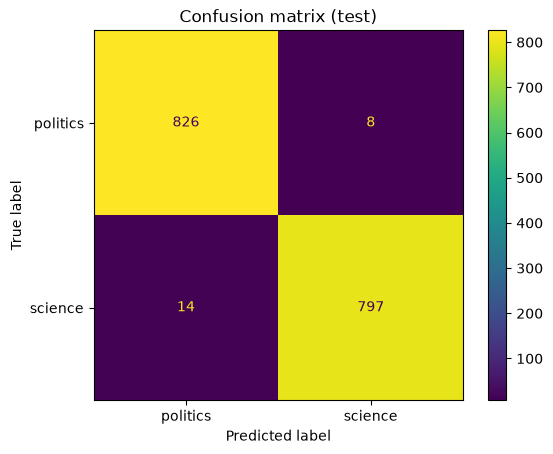

In [20]:
# --- Confusion matrix (test) ---
disp = ConfusionMatrixDisplay.from_estimator(best_sgd_lr, X_test, y_test, display_labels=class_names)
plt.title("Confusion matrix (test)")
plt.grid(False)
plt.show()

2. линейный SVM с подбором С

In [15]:
from sklearn.svm import LinearSVC

param_grid_svm = {
    "clf__C": [0.01, 0.1, 1, 10],
}

svm_pipe = Pipeline([
    ("vec", make_vec()),
    ("clf", LinearSVC(random_state=7, max_iter=5000)),
])

grid_svm = GridSearchCV(
    estimator=svm_pipe,
    param_grid=param_grid_svm,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
grid_svm.fit(X_train, y_train)

print("Лучшие параметры SVM:", grid_svm.best_params_)
print("Лучший macro-F1 на CV:", round(grid_svm.best_score_, 3))

Лучшие параметры SVM: {'clf__C': 1}
Лучший macro-F1 на CV: 0.982


In [16]:
best_svm = grid_svm.best_estimator_

y_val_svm = best_svm.predict(X_val)
y_test_svm = best_svm.predict(X_test)

print("SVM VAL accuracy:", round(accuracy_score(y_val, y_val_svm), 3))
print("SVM VAL macro-F1:", round(f1_score(y_val, y_val_svm, average="macro"), 3))
print()
print("SVM TEST accuracy:", round(accuracy_score(y_test, y_test_svm), 3))
print("SVM TEST macro-F1:", round(f1_score(y_test, y_test_svm, average="macro"), 3))
print("\nОтчёт SVM (test):\n", classification_report(y_test, y_test_svm, target_names=class_names))

SVM VAL accuracy: 0.988
SVM VAL macro-F1: 0.988

SVM TEST accuracy: 0.986
SVM TEST macro-F1: 0.986

Отчёт SVM (test):
               precision    recall  f1-score   support

    politics       0.98      0.99      0.99       834
     science       0.99      0.98      0.99       811

    accuracy                           0.99      1645
   macro avg       0.99      0.99      0.99      1645
weighted avg       0.99      0.99      0.99      1645



In [17]:
def metrics_row(name, y_true_val, y_pred_val, y_true_test, y_pred_test):
    return {
        "модель": name,
        "CV macro-F1": None,
        "VAL accuracy": round(accuracy_score(y_true_val, y_pred_val), 3),
        "VAL macro-F1": round(f1_score(y_true_val, y_pred_val, average="macro"), 3),
        "TEST accuracy": round(accuracy_score(y_true_test, y_pred_test), 3),
        "TEST macro-F1": round(f1_score(y_true_test, y_pred_test, average="macro"), 3),
    }

rows = [
    metrics_row("LogReg (SGD)", y_val, best_sgd_lr.predict(X_val), y_test, best_sgd_lr.predict(X_test)),
    metrics_row("LinearSVC", y_val, y_val_svm, y_test, y_test_svm),
]
rows[0]["CV macro-F1"] = round(grid.best_score_, 3)
rows[1]["CV macro-F1"] = round(grid_svm.best_score_, 3)

results_table = pd.DataFrame(rows)
results_table

,модель,CV macro-F1,VAL accuracy,VAL macro-F1,TEST accuracy,TEST macro-F1
0,LogReg (SGD),0.982,0.985,0.985,0.987,0.987
1,LinearSVC,0.982,0.988,0.988,0.986,0.986


In [18]:
print(results_table.to_string(index=False))

      модель  CV macro-F1  VAL accuracy  VAL macro-F1  TEST accuracy  TEST macro-F1
LogReg (SGD)        0.982         0.985         0.985          0.987          0.987
   LinearSVC        0.982         0.988         0.988          0.986          0.986


3. L1 регуляризация

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

alphas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

models_by_alpha = {}   # alpha -> обученная модель (Pipeline)
results_l1 = []        # (alpha, acc, f1, sparsity)

for a in alphas:
    model = Pipeline([
        ("vec", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            min_df=3,
            ngram_range=(1, 1),
        )),
        ("clf", SGDClassifier(
            loss="log_loss",
            penalty="l1",
            alpha=a,
            learning_rate="constant",
            eta0=0.02,
            max_iter=50,
            tol=1e-6,
            random_state=7
        ))
    ])

    model.fit(X_train, y_train)
    models_by_alpha[a] = model

    y_val_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_val_pred)
    f1  = f1_score(y_val, y_val_pred, average="macro")

    coef = model.named_steps["clf"].coef_.ravel()
    sparsity = (coef == 0).mean()

    results_l1.append((a, acc, f1, sparsity))

print("alpha       acc_val   f1_val   sparsity")
for a, acc, f1, sp in results_l1:
    print(f"{a:<10g} {acc:>7.3f} {f1:>8.3f} {sp:>10.3f}")

# лучший по F1
best_alpha = max(results_l1, key=lambda x: x[2])[0]
best_l1 = models_by_alpha[best_alpha]
print("\nЛучший alpha по F1:", best_alpha)

c:\Users\-\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:744: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\-\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:744: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\-\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:744: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\-\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:744: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing ma

alpha       acc_val   f1_val   sparsity
1e-06        0.982    0.982      0.054
1e-05        0.982    0.982      0.567
0.0001       0.975    0.975      0.964
0.001        0.908    0.908      0.998
0.01         0.507    0.336      1.000

Лучший alpha по F1: 1e-06


In [35]:
best_balanced_alpha_l1, best_balanced_acc_l1, best_balanced_f1_l1, best_balanced_sp_l1 = results_l1[2]
best_balanced_l1 = models_by_alpha[best_balanced_alpha_l1]
print("\nСбалансированный alpha по F1:", best_balanced_alpha_l1, "| f1_val:", best_balanced_f1_l1, "| sparsity:", best_balanced_sp_l1)


Сбалансированный alpha по F1: 0.0001 | f1_val: 0.9750612422233931 | sparsity: 0.9636956965123394


In [36]:
y_test_pred_l1 = best_balanced_l1.predict(X_test)
print("TEST accuracy (L1):", accuracy_score(y_test, y_test_pred_l1))
print("TEST macro-F1 (L1):", f1_score(y_test, y_test_pred_l1, average="macro"))


TEST accuracy (L1): 0.9744680851063829
TEST macro-F1 (L1): 0.9744621867376358


In [37]:
# --- Важные признаки (топ-слова) ---
vec_l1 = best_balanced_l1.named_steps["vec"]
clf_l1 = best_balanced_l1.named_steps["clf"]

feature_names = np.array(vec_l1.get_feature_names_out())
coef = clf_l1.coef_.ravel()  # shape (n_features,)

# Сколько весов стало ровно 0?
zero_frac = (coef == 0).mean()
print(f"Доля нулевых весов (sparsity): {zero_frac:.3f}")

top_k = 20

pos_idx = np.argsort(coef)[-top_k:][::-1]
neg_idx = np.argsort(coef)[:top_k]

print("\nТоп признаков, которые увеличивают p(y=1):")
for w, c in zip(feature_names[pos_idx], coef[pos_idx]):
    print(f"{w:>20s}  {c: .3f}")

print("\nТоп признаков, которые увеличивают p(y=0):")
for w, c in zip(feature_names[neg_idx], coef[neg_idx]):
    print(f"{w:>20s}  {c: .3f}")


Доля нулевых весов (sparsity): 0.964

Топ признаков, которые увеличивают p(y=1):
              ученые   6.939
            компании   6.496
               apple   5.814
                 для   5.474
         специалисты   5.360
            компания   4.994
           microsoft   4.248
             windows   4.221
         космической   3.903
                игры   3.888
                 мкс   3.842
        университета   3.412
                года   3.278
             станции   3.257
               может   3.182
             системы   3.169
               tesla   3.159
          роскосмоса   3.153
             рогозин   3.100
              iphone   3.090

Топ признаков, которые увеличивают p(y=0):
              россии  -7.619
          навального  -6.692
                  он  -6.124
             украины  -5.824
             украине  -5.203
          президента  -4.875
             алексея  -4.850
              страны  -4.451
                 сша  -4.426
                 мид  -4.012
     

In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

def metrics_row(name, params, cv_f1, model):
    y_val_pred = model.predict(X_val)
    y_test_pred = model.predict(X_test)
    coef = model.named_steps["clf"].coef_.ravel()
    return {
        "Модель": name,
        "Параметры": params,
        "CV macro-F1": round(cv_f1, 3) if cv_f1 is not None else "—",
        "VAL macro-F1": round(f1_score(y_val, y_val_pred, average="macro"), 3),
        "TEST accuracy": round(accuracy_score(y_test, y_test_pred), 3),
        "TEST macro-F1": round(f1_score(y_test, y_test_pred, average="macro"), 3),
        "Доля нулевых весов": round((coef == 0).mean(), 3),
    }

# логрегрессия
p_lr = grid.best_params_
row_lr = metrics_row(
    "LogReg (SGD, L2)",
    f"alpha={p_lr['clf__alpha']}, eta0={p_lr['clf__eta0']}, tol={p_lr['clf__tol']}, max_iter={p_lr['clf__max_iter']}",
    grid.best_score_,
    grid.best_estimator_,
)

# LinearSVC
p_svm = grid_svm.best_params_
row_svm = metrics_row(
    "LinearSVC (L2)",
    f"C={p_svm['clf__C']}",
    grid_svm.best_score_,
    grid_svm.best_estimator_,
)

# L1
l1_model = Pipeline([
    ("vec", make_vec()),
    ("clf", SGDClassifier(
        loss="log_loss",
        penalty="l1",
        alpha=1e-4,
        learning_rate="constant",
        eta0=0.02,
        tol=1e-6,
        max_iter=50,
        random_state=7,
    )),
])
l1_model.fit(X_train, y_train)
row_l1 = metrics_row("LogReg (SGD, L1)", "alpha=0.0001", None, l1_model)

results_table = pd.DataFrame([row_lr, row_svm, row_l1])
display(results_table)

c:\Users\-\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:744: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,Модель,Параметры,CV macro-F1,VAL macro-F1,TEST accuracy,TEST macro-F1,Доля нулевых весов
0,"LogReg (SGD, L2)","alpha=1e-05, eta0=0.1, tol=0.0001, max_iter=50",0.982,0.985,0.987,0.987,0.000
1,LinearSVC (L2),C=1,0.982,0.988,0.986,0.986,0.059
2,"LogReg (SGD, L1)",alpha=0.0001,—,0.976,0.976,0.976,0.960


## Выводы

Все три модели показывают качество 0.97–0.99 macro-F1, то есть на этом датасете классы хорошо разделяются словами, и даже простая линейная модель с TF-IDF справляется почти идеально. Логрегрессия и LinearSVC практически равны: SVM чуть лучше на валидации (0.988 против 0.985), а логрегрессия чуть лучше на тесте (0.987 против 0.986), и разница в тысячных долях не значима. L1-регуляризация с alpha=1e-4 обнуляет около 96% весов и оставляет примерно 1100 признаков из 31856, а цена этого составляет около 1,3 п.п. macro-F1 на тесте, что делает модель намного проще для интерпретации. 